In [1]:
import pandas as pd
import numpy as np

labeled = pd.read_json("./corpus_labeled_qs.json")
labeled.head()

,id,annotations,file_upload,drafts,predictions,data,meta,created_at,updated_at,inner_id,total_annotations,cancelled_annotations,total_predictions,comment_count,unresolved_comment_count,last_comment_updated_at,project,updated_by,comment_authors
0,1,"[{'id': 1, 'completed_by': 1, 'result': [{'val...",ebbcffa1-corpus.csv,[],[],"{'Unnamed: 0': 0, 'questions': 'Van: communica...",{},2025-08-18 14:03:20.242363+00:00,2025-08-18 14:15:08.037105+00:00,1,1,0,0,0,0,NaT,1,1,[]
1,2,"[{'id': 2, 'completed_by': 1, 'result': [{'val...",ebbcffa1-corpus.csv,[],[],"{'Unnamed: 0': 1, 'questions': 'De : communica...",{},2025-08-18 14:03:20.242405+00:00,2025-08-18 14:18:05.278242+00:00,2,1,0,0,0,0,NaT,1,1,[]
2,3,"[{'id': 3, 'completed_by': 1, 'result': [{'val...",ebbcffa1-corpus.csv,[],[],"{'Unnamed: 0': 2, 'questions': '**Van:** loeks...",{},2025-08-18 14:03:20.242428+00:00,2025-08-18 14:18:56.797454+00:00,3,1,0,0,0,0,NaT,1,1,[]
3,4,"[{'id': 4, 'completed_by': 1, 'result': [{'val...",ebbcffa1-corpus.csv,[],[],"{'Unnamed: 0': 3, 'questions': '**De :** delp...",{},2025-08-18 14:03:20.242455+00:00,2025-08-18 14:19:23.135418+00:00,4,1,0,0,0,0,NaT,1,1,[]
4,5,"[{'id': 5, 'completed_by': 1, 'result': [{'val...",ebbcffa1-corpus.csv,[],[],"{'Unnamed: 0': 4, 'questions': 'De : communica...",{},2025-08-18 14:03:20.242475+00:00,2025-08-18 14:19:39.191617+00:00,5,1,0,0,0,0,NaT,1,1,[]


In [2]:
labeled.columns

Index(['id', 'annotations', 'file_upload', 'drafts', 'predictions', 'data',
       'meta', 'created_at', 'updated_at', 'inner_id', 'total_annotations',
       'cancelled_annotations', 'total_predictions', 'comment_count',
       'unresolved_comment_count', 'last_comment_updated_at', 'project',
       'updated_by', 'comment_authors'],
      dtype='object')

In [3]:
labeled[["id", "data", "annotations"]].set_index("id").head()

,data,annotations
id,,
1,"{'Unnamed: 0': 0, 'questions': 'Van: communica...","[{'id': 1, 'completed_by': 1, 'result': [{'val..."
2,"{'Unnamed: 0': 1, 'questions': 'De : communica...","[{'id': 2, 'completed_by': 1, 'result': [{'val..."
3,"{'Unnamed: 0': 2, 'questions': '**Van:** loeks...","[{'id': 3, 'completed_by': 1, 'result': [{'val..."
4,"{'Unnamed: 0': 3, 'questions': '**De :** delp...","[{'id': 4, 'completed_by': 1, 'result': [{'val..."
5,"{'Unnamed: 0': 4, 'questions': 'De : communica...","[{'id': 5, 'completed_by': 1, 'result': [{'val..."


In [4]:
def annotation_(df):
    """grab annotation."""
    return df.annotations.map(lambda x: x[0]["result"][0]["value"]["taxonomy"][0][-1])

def question_(df):
    """grab questions from the json"""
    return df.data.map(lambda x: x["questions"])

def response_(df):
    """graph responses from the json"""
    return df.data.map(lambda x: x["responses"])

<Axes: ylabel='question'>

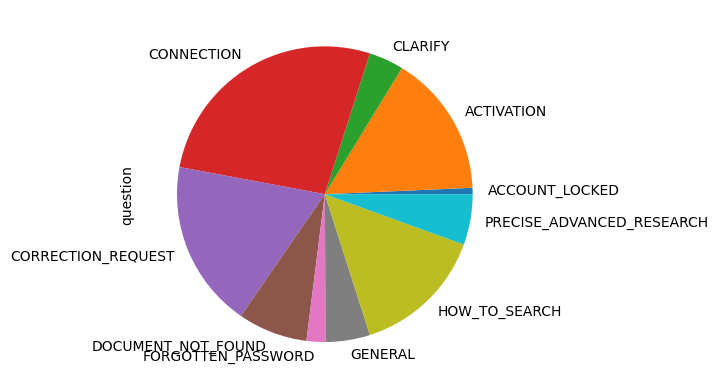

In [5]:
df = pd.DataFrame({"question": question_(labeled), "response": response_(labeled), "request_type": annotation_(labeled)})
df["request_type"].astype("category")
df.to_csv("corpus_qlabel_clean.csv")
df[['question', "request_type"]].groupby("request_type").count().plot.pie(y="question", legend=None, ylabel=None)